#### Plot comparisons of the GBSA of two systems

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# --------------------------------------------------
# Load the six trajectories
# --------------------------------------------------

dyn_ids = [828, 1033]
replicates = [1, 2, 3] # rep '1' of 1033 is originally rep '6' in the MD files (renamed manually after GBSA analysis)
results_path = "/home/mlopez/users/mlopez/free_energies/gbsa_traj_pipeline/results/non_loaded_trajs"

data = {}

for dyn in dyn_ids:
    data[dyn] = {}
    
    for rep in replicates:
        filename = f"Energy_{rep}_trj_{dyn}.csv"
        filepath = f"{results_path}/{dyn}/fms_600_v2/extra{rep}_trj_{dyn}_UNIGBSA/{filename}"
        df = pd.read_csv(filepath)
        
        data[dyn][rep] = df
        
        print(f"Dyn {dyn}, Rep {rep}: {len(df)} frames")

Dyn 828, Rep 1: 600 frames
Dyn 828, Rep 2: 600 frames
Dyn 828, Rep 3: 600 frames
Dyn 1033, Rep 1: 600 frames
Dyn 1033, Rep 2: 600 frames
Dyn 1033, Rep 3: 600 frames


In [5]:
summary = []

for dyn in dyn_ids:
    for rep in replicates:
        df = data[dyn][rep]
        
        summary.append({
            "Dyn": str(dyn),
            "Replicate": rep,
            "TOTAL_mean": df["TOTAL"].mean(),
            "TOTAL_std": df["TOTAL"].std(),
        })

summary_df = pd.DataFrame(summary)

summary_df

,Dyn,Replicate,TOTAL_mean,TOTAL_std
0,828,1,-36.156669,3.663707
1,828,2,-41.625009,3.371952
2,828,3,-36.399469,3.805292
3,1033,1,-28.940291,3.157400
4,1033,2,-30.184557,3.281380
5,1033,3,-30.159172,3.407347


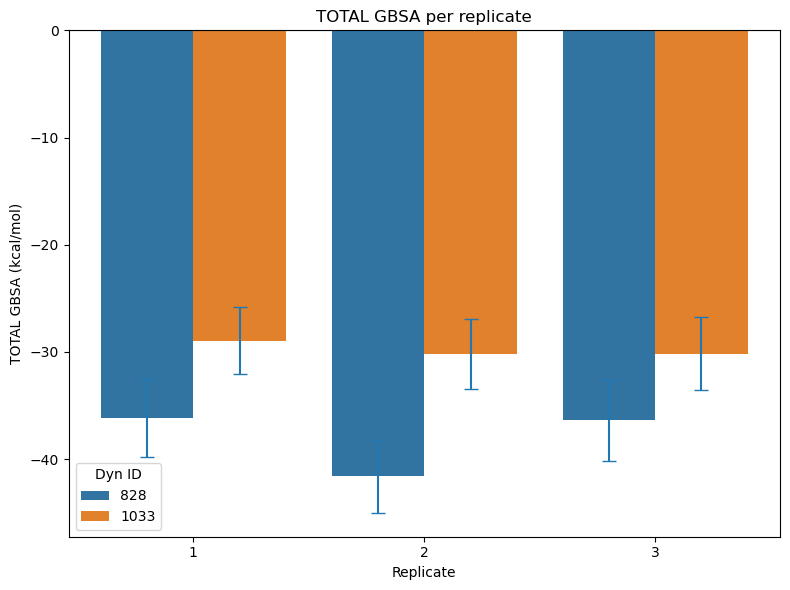

In [6]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=summary_df,
    x="Replicate",
    y="TOTAL_mean",
    hue="Dyn",
    errorbar=None
)

# Add SD error bars manually
for i, row in summary_df.iterrows():
    # Determine x position based on seaborn dodge
    rep_idx = row["Replicate"] - 1
    
    if row["Dyn"] == "828":
        x = rep_idx - 0.2
    else:
        x = rep_idx + 0.2
    
    plt.errorbar(
        x,
        row["TOTAL_mean"],
        yerr=row["TOTAL_std"],
        fmt="none",
        capsize=5,
        linewidth=1.5
    )

plt.axhline(0, linewidth=0.8)
plt.ylabel("TOTAL GBSA (kcal/mol)")
plt.xlabel("Replicate")
plt.title("TOTAL GBSA per replicate")
plt.legend(title="Dyn ID")
plt.tight_layout()
plt.show()

In [7]:
all_total = []

for dyn in dyn_ids:
    for rep in replicates:
        df = data[dyn][rep]
        
        tmp = pd.DataFrame({
            "Dyn": str(dyn),
            "Replicate": f"Rep {rep}",
            "TOTAL": df["TOTAL"]
        })
        
        all_total.append(tmp)

total_df = pd.concat(all_total, ignore_index=True)

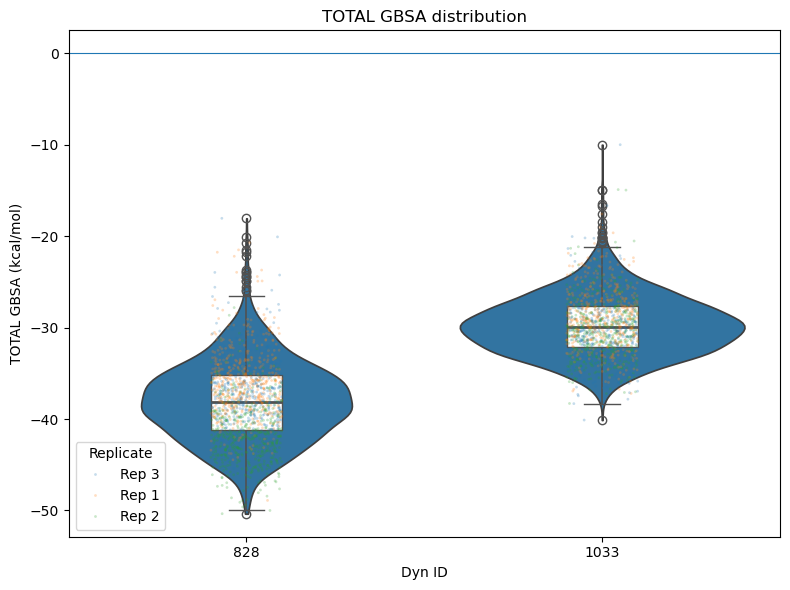

In [8]:
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=total_df,
    x="Dyn",
    y="TOTAL",
    inner=None,
    cut=0
)

sns.boxplot(
    data=total_df,
    x="Dyn",
    y="TOTAL",
    width=0.2,
    showcaps=True,
    boxprops={"facecolor": "white"},
    whiskerprops={"linewidth": 1.2},
    medianprops={"linewidth": 2}
)

sns.stripplot(
    data=total_df.sample(min(3000, len(total_df)), random_state=42),
    x="Dyn",
    y="TOTAL",
    hue="Replicate",
    alpha=0.25,
    size=2,
    dodge=False
)

plt.axhline(0, linewidth=0.8)
plt.ylabel("TOTAL GBSA (kcal/mol)")
plt.xlabel("Dyn ID")
plt.title("TOTAL GBSA distribution")
plt.legend(title="Replicate")
plt.tight_layout()
plt.show()

In [10]:
components = [
    "Van der Waals",
    "Electrostatic",
    "Polar Solvation",
    "Non-Polar Solvation",
    "TOTAL"
]

In [ ]:
component_summary = [] # mean across frames for each replicate

for dyn in dyn_ids:
    for rep in replicates:
        df = data[dyn][rep]
        
        for component in components:
            component_summary.append({
                "Dyn": str(dyn),
                "Replicate": rep,
                "Component": component,
                "Mean": df[component].mean(),
                "SD": df[component].std()
            })

component_df = pd.DataFrame(component_summary)

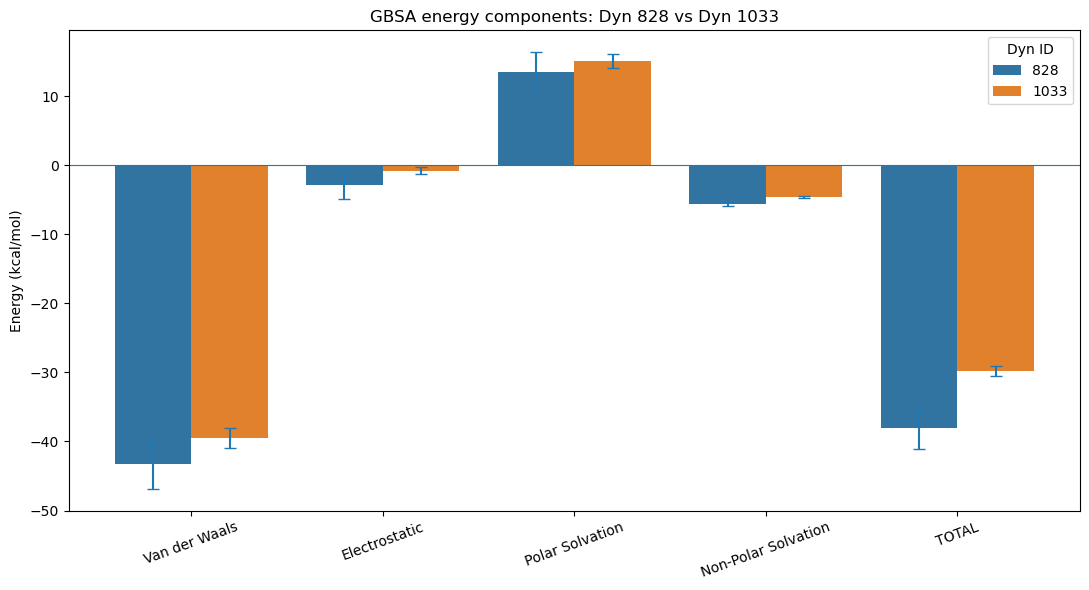

In [ ]:
plt.figure(figsize=(11, 6)) # plot the DYN averages with replicate variability.

sns.barplot(
    data=component_df,
    x="Component",
    y="Mean",
    hue="Dyn",
    errorbar=None
)

# Add replicate-level SD error bars
n_dyn = len(dyn_ids)
width = 0.8 / n_dyn

for i, component in enumerate(components):
    
    for j, dyn in enumerate(dyn_ids):
        
        row = component_df[
            (component_df["Component"] == component) &
            (component_df["Dyn"] == str(dyn))
        ]
        
        mean = row["Mean"].mean()
        sd = row["Mean"].std()
        
        x = i - 0.4 + width/2 + j * width
        
        plt.errorbar(
            x,
            mean,
            yerr=sd,
            fmt="none",
            capsize=4,
            linewidth=1.5
        )

plt.axhline(0, linewidth=0.8)
plt.ylabel("Energy (kcal/mol)")
plt.xlabel("")
plt.title("GBSA energy components: Dyn 828 vs Dyn 1033")
plt.xticks(rotation=20)
plt.legend(title="Dyn ID")
plt.tight_layout()
plt.show()

#### Are there statistical differences?
Is the difference in GBSA between 828 and 1033 reproducible across independent trajectories?

In [14]:
summary_df

,Dyn,Replicate,TOTAL_mean,TOTAL_std
0,828,1,-36.156669,3.663707
1,828,2,-41.625009,3.371952
2,828,3,-36.399469,3.805292
3,1033,1,-28.940291,3.157400
4,1033,2,-30.184557,3.281380
5,1033,3,-30.159172,3.407347


In [15]:
# Put DYNs side by side
pivot = summary_df.pivot(
    index="Replicate",
    columns="Dyn",
    values="TOTAL_mean"
)

pivot["Difference_828_minus_1033"] = pivot[str(828)] - pivot[str(1033)]

print(pivot)

Dyn             1033        828  Difference_828_minus_1033
Replicate                                                 
1         -28.940291 -36.156669                  -7.216378
2         -30.184557 -41.625009                 -11.440452
3         -30.159172 -36.399469                  -6.240297


In [17]:
from scipy import stats
t_stat, p_value = stats.ttest_rel(
    pivot[str(828)],
    pivot[str(1033)]
)

print(f"Paired t-test: t = {t_stat:.3f}, p = {p_value:.4f}")

Paired t-test: t = -5.201, p = 0.0350
